# Nhận diện chữ số viết tay bằng Neural Network tự cài đặt (from scratch) + Webcam realtime


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

np.random.seed(42)


## 1. Load và chuẩn bị dữ liệu (`load_digits` - dataset có sẵn của Sklearn)

In [3]:
IMG_SIZE = 8  # kich thuoc anh cua load_digits

digits = load_digits()
X = digits.data / 16.0                     # chuan hoa pixel ve [0, 1] (goc la [0, 16])
y = digits.target                           # nhan 0..9

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "X_test:", X_test.shape)


X_train: (1437, 64) X_test: (360, 64)


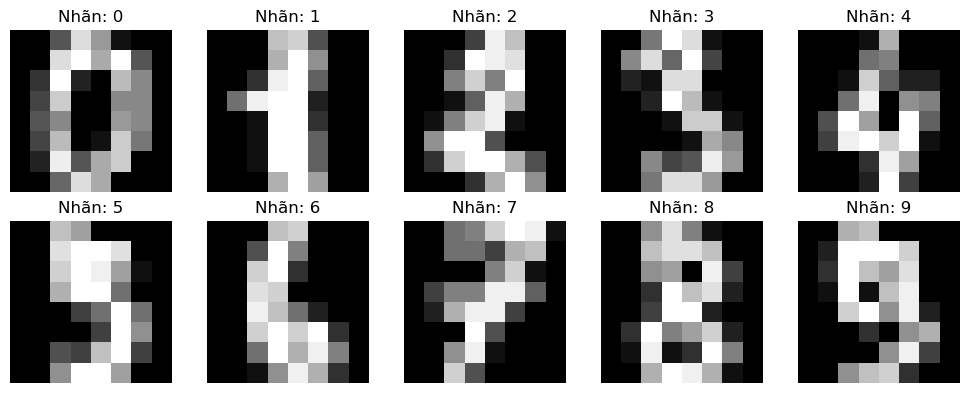

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Nhãn: {digits.target[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 1.1 Data augmentation cho tập train (chỉ dùng lại `load_digits`, không thêm dữ liệu ngoài)

Chữ số trong `load_digits` đã được scan rất chuẩn (canh giữa, không nghiêng), nhưng chữ số bạn viết qua camera thường **lệch tâm, hơi nghiêng, cỡ không đều**. Để model quen với những biến thể này, ta tạo thêm bản sao của tập train với:
- dịch ngang/dọc ngẫu nhiên ±1 pixel
- xoay ngẫu nhiên ±12 độ

**Chỉ augment tập train**, giữ nguyên tập test để đánh giá công bằng, không bị rò rỉ dữ liệu (data leakage).


In [5]:
def augment_digits(X, y, n_aug=2, max_shift=1, max_rotate=12, size=IMG_SIZE, seed=42):
    '''
    Tao them ban sao cua tap du lieu voi dich nhe + xoay nhe,
    giup model quen voi chu so bi lech tam / nghieng khi viet tay qua camera.
    '''
    rng = np.random.default_rng(seed)
    X_list, y_list = [X], [y]
    for _ in range(n_aug):
        X_variant = []
        for img in X:
            img2d = img.reshape(size, size)
            dx, dy = rng.integers(-max_shift, max_shift + 1, size=2)
            img2d = ndimage.shift(img2d, shift=(dy, dx), mode="constant", cval=0.0)
            angle = rng.uniform(-max_rotate, max_rotate)
            img2d = ndimage.rotate(img2d, angle, reshape=False, mode="constant", cval=0.0)
            img2d = np.clip(img2d, 0.0, 1.0)
            X_variant.append(img2d.flatten())
        X_list.append(np.array(X_variant))
        y_list.append(y.copy())
    return np.vstack(X_list), np.concatenate(y_list)

X_train, y_train = augment_digits(X_train, y_train, n_aug=2, max_shift=1, max_rotate=12)
print("X_train sau augmentation:", X_train.shape)


X_train sau augmentation: (4311, 64)


In [6]:
import cv2

def make_synthetic_seven(size=32, thickness=3, tick=False, seed=None):
    rng = np.random.default_rng(seed)
    canvas = np.zeros((size, size), dtype=np.uint8)

    top_y = rng.integers(3, 6)
    left_x = rng.integers(4, 8)
    right_x = size - rng.integers(4, 8)
    bottom_y = size - rng.integers(2, 5)
    bottom_x = left_x + rng.integers(2, 8)

    th = max(1, thickness + rng.integers(-1, 2))

    cv2.line(canvas, (left_x, top_y), (right_x, top_y), 255, th)
    cv2.line(canvas, (right_x, top_y), (bottom_x, bottom_y), 255, th)

    if tick:
        mid_y = (top_y + bottom_y) // 2 + rng.integers(-2, 3)
        tick_len = rng.integers(4, 8)
        cx = (right_x + bottom_x) // 2
        cv2.line(canvas, (max(cx - tick_len, 0), mid_y),
                  (min(cx + 2, size - 1), mid_y), 255, max(th - 1, 1))

    return canvas


def canvas_to_8x8_grid(canvas, grid=8, block=None):
    size = canvas.shape[0]
    block = block or size // grid
    out = np.zeros((grid, grid), dtype=np.float64)
    for i in range(grid):
        for j in range(grid):
            region = canvas[i * block:(i + 1) * block, j * block:(j + 1) * block]
            out[i, j] = region.sum() / 255.0
    if out.max() > 0:
        out = out / out.max() * 16.0
    return out


def generate_synthetic_sevens(n=300, seed=42, thickness_range=(2, 7)):
    X_syn, y_syn = [], []
    rng = np.random.default_rng(seed)
    for i in range(n):
        tick = bool(rng.integers(0, 2))
        thickness = int(rng.integers(thickness_range[0], thickness_range[1] + 1))
        canvas = make_synthetic_seven(seed=seed + i, tick=tick, thickness=thickness)
        angle = rng.uniform(-10, 10)
        M = cv2.getRotationMatrix2D((16, 16), angle, 1.0)
        canvas = cv2.warpAffine(canvas, M, (32, 32))
        grid = canvas_to_8x8_grid(canvas)
        X_syn.append((grid / 16.0).flatten())
        y_syn.append(7)
    return np.array(X_syn), np.array(y_syn)


X_syn, y_syn = generate_synthetic_sevens(n=300, seed=42, thickness_range=(2, 7))
X_train = np.vstack([X_train, X_syn])
y_train = np.concatenate([y_train, y_syn])
print("X_train sau khi them 7 tong hop (mong + day):", X_train.shape)

X_train sau khi them 7 tong hop (mong + day): (4611, 64)


In [7]:
def one_hot(y, num_classes=10):
    oh = np.zeros((y.shape[0], num_classes))
    oh[np.arange(y.shape[0]), y] = 1
    return oh

y_train_oh = one_hot(y_train)
y_test_oh = one_hot(y_test)


## 2. Cài đặt Neural Network từ đầu

Kiến trúc: `Input(64) -> Dense(ReLU) -> Dense(ReLU) -> Dense(Softmax, 10)`

In [8]:
class NeuralNetwork:
    def __init__(self, layer_sizes, lr=0.1, seed=42):
        '''
        layer_sizes: list so neuron moi lop, vd [64, 128, 64, 10]
        '''
        rng = np.random.default_rng(seed)
        self.layer_sizes = layer_sizes
        self.lr = lr
        self.weights = []
        self.biases = []
        for i in range(len(layer_sizes) - 1):
            fan_in, fan_out = layer_sizes[i], layer_sizes[i + 1]
            limit = np.sqrt(2.0 / fan_in)          # He init - phu hop ReLU
            W = rng.normal(0, limit, size=(fan_in, fan_out))
            b = np.zeros((1, fan_out))
            self.weights.append(W)
            self.biases.append(b)

    # ---- activations ----
    def relu(self, z):
        return np.maximum(0, z)

    def relu_deriv(self, z):
        return (z > 0).astype(float)

    def softmax(self, z):
        z = z - np.max(z, axis=1, keepdims=True)   # on dinh so hoc
        exp = np.exp(z)
        return exp / np.sum(exp, axis=1, keepdims=True)

    # ---- forward ----
    def forward(self, X):
        self.z_list = []
        self.a_list = [X]
        a = X
        L = len(self.weights)
        for i in range(L):
            z = a @ self.weights[i] + self.biases[i]
            self.z_list.append(z)
            a = self.softmax(z) if i == L - 1 else self.relu(z)
            self.a_list.append(a)
        return a

    def compute_loss(self, y_pred, y_true_oh):
        m = y_true_oh.shape[0]
        eps = 1e-9
        return -np.sum(y_true_oh * np.log(y_pred + eps)) / m

    # ---- backward ----
    def backward(self, y_true_oh):
        m = y_true_oh.shape[0]
        L = len(self.weights)
        grads_W = [None] * L
        grads_b = [None] * L

        # dao ham loss theo z cua lop cuoi (softmax + cross-entropy)
        dz = (self.a_list[-1] - y_true_oh) / m
        for i in reversed(range(L)):
            a_prev = self.a_list[i]
            grads_W[i] = a_prev.T @ dz
            grads_b[i] = np.sum(dz, axis=0, keepdims=True)
            if i > 0:
                da_prev = dz @ self.weights[i].T
                dz = da_prev * self.relu_deriv(self.z_list[i - 1])
        return grads_W, grads_b

    def update(self, grads_W, grads_b):
        for i in range(len(self.weights)):
            self.weights[i] -= self.lr * grads_W[i]
            self.biases[i] -= self.lr * grads_b[i]

    # ---- inference ----
    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

    def predict_proba(self, X):
        return self.forward(X)

    def accuracy(self, X, y):
        return np.mean(self.predict(X) == y)

    # ---- training loop ----
    def train(self, X_train, y_train_oh, y_train_labels, X_val, y_val,
               epochs=300, batch_size=32, verbose=True):
        history = {"loss": [], "train_acc": [], "val_acc": []}
        n = X_train.shape[0]
        for epoch in range(epochs):
            perm = np.random.permutation(n)
            X_shuf, y_shuf = X_train[perm], y_train_oh[perm]

            epoch_loss, n_batches = 0.0, 0
            for start in range(0, n, batch_size):
                end = start + batch_size
                X_batch, y_batch = X_shuf[start:end], y_shuf[start:end]

                y_pred = self.forward(X_batch)
                epoch_loss += self.compute_loss(y_pred, y_batch)
                n_batches += 1

                grads_W, grads_b = self.backward(y_batch)
                self.update(grads_W, grads_b)

            avg_loss = epoch_loss / n_batches
            train_acc = self.accuracy(X_train, y_train_labels)
            val_acc = self.accuracy(X_val, y_val)

            history["loss"].append(avg_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)

            if verbose and (epoch % 20 == 0 or epoch == epochs - 1):
                print(f"Epoch {epoch+1:3d}/{epochs} - loss: {avg_loss:.4f} "
                      f"- train_acc: {train_acc:.4f} - val_acc: {val_acc:.4f}")
        return history


## 3. Huấn luyện mô hình

In [9]:
model = NeuralNetwork(layer_sizes=[64, 128, 64, 10], lr=0.5, seed=42)

history = model.train(
    X_train, y_train_oh, y_train,
    X_test, y_test,
    epochs=300, batch_size=32, verbose=True
)


Epoch   1/300 - loss: 1.2865 - train_acc: 0.3993 - val_acc: 0.6111
Epoch  21/300 - loss: 0.0614 - train_acc: 0.9803 - val_acc: 0.9556
Epoch  41/300 - loss: 0.0006 - train_acc: 1.0000 - val_acc: 0.9861
Epoch  61/300 - loss: 0.0003 - train_acc: 1.0000 - val_acc: 0.9861
Epoch  81/300 - loss: 0.0002 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 101/300 - loss: 0.0002 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 121/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 141/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 161/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 181/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 201/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 221/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 241/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 261/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.9861
Epoch 281/300 - loss: 0.0001 - train_acc: 1.0000 - val_acc: 0.

## 4. Đánh giá kết quả

In [10]:
test_acc = model.accuracy(X_test, y_test)
print(f"Do chinh xac tren tap test: {test_acc:.4f}")

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))


Do chinh xac tren tap test: 0.9861
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9474    1.0000    0.9730        36
           2     1.0000    1.0000    1.0000        35
           3     0.9737    1.0000    0.9867        37
           4     1.0000    1.0000    1.0000        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    0.9444    0.9714        36
           7     1.0000    1.0000    1.0000        36
           8     0.9697    0.9143    0.9412        35
           9     1.0000    1.0000    1.0000        36

    accuracy                         0.9861       360
   macro avg     0.9864    0.9859    0.9859       360
weighted avg     0.9864    0.9861    0.9860       360



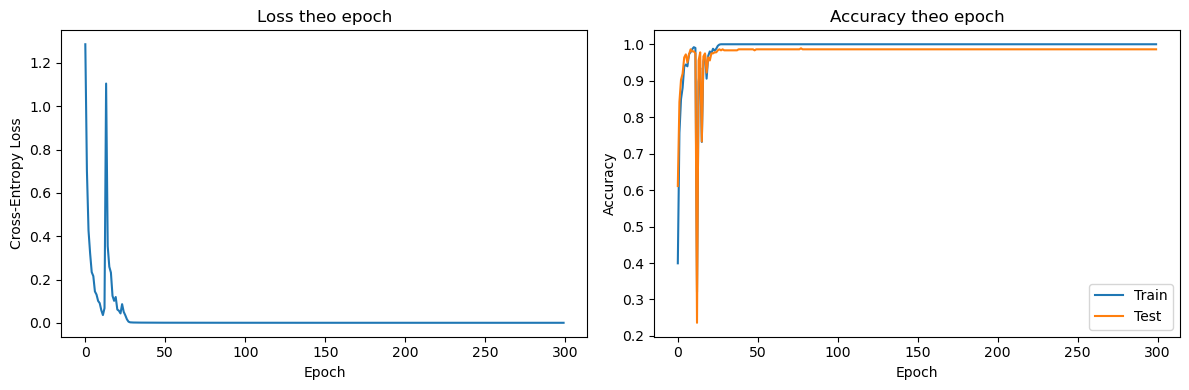

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["loss"])
axes[0].set_title("Loss theo epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Test")
axes[1].set_title("Accuracy theo epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


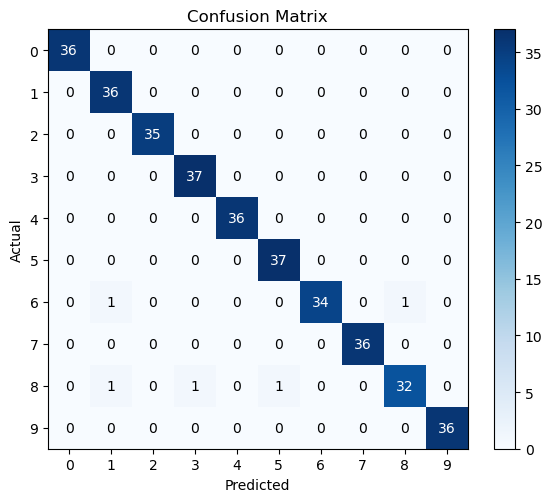

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                  color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(10))
plt.yticks(range(10))
plt.tight_layout()
plt.show()


## 5. Xem thử vài dự đoán

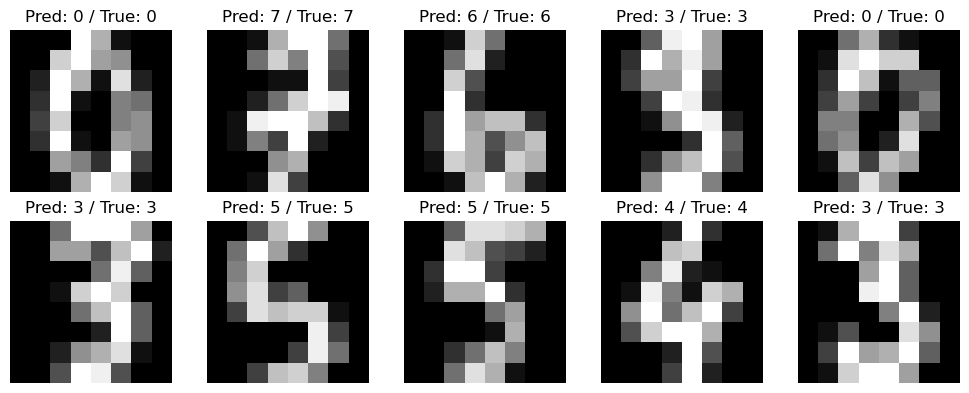

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
idx = np.random.choice(len(X_test), 10, replace=False)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_test[i].reshape(IMG_SIZE, IMG_SIZE), cmap="gray")
    ax.set_title(f"Pred: {y_pred[i]} / True: {y_test[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 6. Nhận diện qua Camera — tiền xử lý theo đúng cách `load_digits` được tạo ra


In [25]:
import cv2
import numpy as np
import threading
import time

CAMERA_CONFIG = {
    "IP_WEBCAM_URL": "http://<IP-DIEN-THOAI>:8080/video",
    "CAP_WIDTH": 640,
    "CAP_HEIGHT": 480,
    "WINDOW_WIDTH": 1000,
    "WINDOW_HEIGHT": 700,
    "ROI_SIZE": 300,
    "THRESHOLD": True,
    "INVERT": True,
    "DENOISE": True,
    "BBOX_MARGIN_RATIO": 0.18,
}


def _estimate_stroke_thickness(binary_255):
    mask = (binary_255 > 0).astype(np.uint8)
    if mask.sum() == 0:
        return 0.0
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    return 2 * dist[mask > 0].mean()


def _crop_to_ink_bbox(binary_255, margin_ratio=0.18):
    ys, xs = np.where(binary_255 > 0)
    if ys.size == 0:
        return None
    y1, y2 = ys.min(), ys.max()
    x1, x2 = xs.min(), xs.max()
    side = max(y2 - y1 + 1, x2 - x1 + 1)
    margin = int(round(side * margin_ratio))
    H, W = binary_255.shape
    y1 = max(y1 - margin, 0); y2 = min(y2 + margin, H - 1)
    x1 = max(x1 - margin, 0); x2 = min(x2 + margin, W - 1)
    return binary_255[y1:y2 + 1, x1:x2 + 1]


def to_digits_format(binary_255, canvas_size=32, grid=8, block=4, bbox_margin_ratio=0.18):
    cropped = _crop_to_ink_bbox(binary_255, margin_ratio=bbox_margin_ratio)
    if cropped is None or cropped.size == 0:
        return np.zeros((grid, grid), dtype=np.float64)
    binary_255 = cropped

    h, w = binary_255.shape
    side_orig = max(h, w)
    target_thickness = side_orig / canvas_size * 1.5 * 2
    stroke_thickness = _estimate_stroke_thickness(binary_255)

    if 0 < stroke_thickness < target_thickness * 0.85:
        deficit = target_thickness - stroke_thickness
        k = max(3, int(round(deficit)))
        if k % 2 == 0: k += 1
        thick = cv2.dilate(binary_255, np.ones((k, k), np.uint8), iterations=1)
    elif stroke_thickness > target_thickness * 1.3:
        excess = stroke_thickness - target_thickness
        k = max(3, int(round(excess)))
        if k % 2 == 0: k += 1
        thick = cv2.erode(binary_255, np.ones((k, k), np.uint8), iterations=1)
    else:
        thick = binary_255.copy()

    h, w = thick.shape
    side = max(h, w)
    pad_top = (side - h) // 2; pad_bottom = side - h - pad_top
    pad_left = (side - w) // 2; pad_right = side - w - pad_left
    square = cv2.copyMakeBorder(thick, pad_top, pad_bottom, pad_left, pad_right,
                                 cv2.BORDER_CONSTANT, value=0)
    canvas = cv2.resize(square, (canvas_size, canvas_size), interpolation=cv2.INTER_AREA)

    M_mom = cv2.moments(canvas)
    if M_mom["m00"] > 0:
        cx = M_mom["m10"] / M_mom["m00"]; cy = M_mom["m01"] / M_mom["m00"]
        shift_x = int(round(canvas_size / 2 - cx)); shift_y = int(round(canvas_size / 2 - cy))
        canvas = cv2.warpAffine(canvas, np.float32([[1, 0, shift_x], [0, 1, shift_y]]),
                                 (canvas_size, canvas_size))

    out = np.zeros((grid, grid), dtype=np.float64)
    for i in range(grid):
        for j in range(grid):
            out[i, j] = canvas[i*block:(i+1)*block, j*block:(j+1)*block].sum() / 255.0
    return out


def preprocess_roi_to_digit(roi_bgr, cam_cfg):
    gray = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2GRAY)
    if cam_cfg.get("DENOISE", True):
        gray = cv2.medianBlur(gray, 3)
    if cam_cfg["THRESHOLD"]:
        _, gray = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if cam_cfg["INVERT"]:
        gray = 255 - gray
    margin_ratio = cam_cfg.get("BBOX_MARGIN_RATIO", 0.18)
    small_16 = to_digits_format(gray, bbox_margin_ratio=margin_ratio)
    vec = (small_16 / 16.0).reshape(1, -1)
    small_view = (small_16 * (255.0 / 16)).astype(np.uint8)
    return vec, small_view


def is_frame_corrupted(frame, black_ratio_threshold=0.85):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    return np.mean(gray < 10) > black_ratio_threshold


class CameraStream:
    def __init__(self, url, width=None, height=None):
        self.cap = cv2.VideoCapture(url)
        if width: self.cap.set(cv2.CAP_PROP_FRAME_WIDTH, width)
        if height: self.cap.set(cv2.CAP_PROP_FRAME_HEIGHT, height)
        try: self.cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        except Exception: pass
        self.frame = None; self.ret = False; self.stopped = False
        self.lock = threading.Lock()
        self.thread = threading.Thread(target=self._update, daemon=True)

    def start(self):
        self.thread.start(); return self

    def _update(self):
        while not self.stopped:
            ret, frame = self.cap.read()
            with self.lock: self.ret, self.frame = ret, frame
            if not ret: time.sleep(0.05)

    def read(self):
        with self.lock:
            return self.ret, (self.frame.copy() if self.frame is not None else None)

    def isOpened(self): return self.cap.isOpened()

    def stop(self):
        self.stopped = True; self.thread.join(timeout=1); self.cap.release()


def run_camera_recognition(model, cam_cfg):
    stream = CameraStream(cam_cfg["IP_WEBCAM_URL"], width=cam_cfg.get("CAP_WIDTH"),
                           height=cam_cfg.get("CAP_HEIGHT")).start()
    if not stream.isOpened():
        print("Khong mo duoc stream. Kiem tra lai IP_WEBCAM_URL va mang WiFi.")
        return
    print("Dang chay nhan dien camera. Nhan 'q' de thoat.")
    window_name = "Digit recognition - IP Webcam (nhan 'q' de thoat)"
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(window_name, cam_cfg["WINDOW_WIDTH"], cam_cfg["WINDOW_HEIGHT"])
    last_good_frame = None; frame_count = 0; predict_every_n = 3
    last_pred, last_conf = None, None
    try:
        while True:
            ret, frame = stream.read()
            if not ret or frame is None: continue
            if is_frame_corrupted(frame):
                if last_good_frame is not None: cv2.imshow(window_name, last_good_frame)
                if cv2.waitKey(1) & 0xFF == ord('q'): break
                continue
            h, w = frame.shape[:2]
            s = cam_cfg["ROI_SIZE"]
            cx, cy = w // 2, h // 2
            x1, y1 = max(cx - s // 2, 0), max(cy - s // 2, 0)
            x2, y2 = min(cx + s // 2, w), min(cy + s // 2, h)
            roi = frame[y1:y2, x1:x2]
            frame_count += 1
            if roi.size > 0 and frame_count % predict_every_n == 0:
                vec, small_view = preprocess_roi_to_digit(roi, cam_cfg)
                probs = model.predict_proba(vec)[0]
                last_pred = int(np.argmax(probs)); last_conf = float(probs[last_pred])
            if roi.size > 0 and last_pred is not None:
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
                label = f"{last_pred} ({last_conf*100:.1f}%)"
                cv2.putText(frame, label, (x1, max(y1 - 10, 20)),
                            cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
                _, small_view = preprocess_roi_to_digit(roi, cam_cfg)
                preview = cv2.resize(small_view, (128, 128), interpolation=cv2.INTER_NEAREST)
                frame[10:138, 10:138] = cv2.cvtColor(preview, cv2.COLOR_GRAY2BGR)
            cv2.imshow(window_name, frame)
            cv2.resizeWindow(window_name, cam_cfg["WINDOW_WIDTH"], cam_cfg["WINDOW_HEIGHT"])
            last_good_frame = frame
            if cv2.waitKey(1) & 0xFF == ord('q'): break
    finally:
        stream.stop(); cv2.destroyAllWindows()

In [26]:
# Nho sua IP_WEBCAM_URL trong CAMERA_CONFIG o cell tren truoc khi chay
run_camera_recognition(model, CAMERA_CONFIG)


Dang chay nhan dien camera. Nhan 'q' de thoat.


KeyboardInterrupt: 